In [268]:
from hofmann import StructureScene
from hofmann import CellEdgeStyle, RenderStyle
from pymatgen.io.ase import AseAtomsAdaptor as aaa
import matplotlib.pyplot as plt
from chgnet.model.dynamics import CHGNetCalculator
from ase.calculators.emt import EMT
from smilesbox.smilesbox import SMILESbox
from ase.build import sort 

from claude_code.neb_runner import NEBRunner
from claude_code.complex_builder import ComplexBuilder, ElementPair

Overall reaction: 2 NO + O2 = 2 NO2 

assuming intermediate steps: 

1. NO + O2 = NO3 
2. NO3 + NO = 2 NO2 

In [276]:
# Pathway 2  (2 elementary steps, intermediates: N2O4  MD score: 0.0019)
#  Step 1:  2NO2 -> N2O4
#  Step 2:  H2O + N2O4 -> HNO2 + HNO3
#
species = {
    "H2O": "O",
    # "O3": "[O-][O+]=O",
    "NO2": "N(=O)[O]",
    # "HO2":"O[O-]",
    # "NO":"[N]=O",
    "HNO2": "N(=O)O",
    "HNO3": "[N+](=O)(O)[O-]",
    # "O2":"O=O"
    # "NO3":"[N+](=O)([O-])[O-]",
    "N2O4": "[N+](=O)([N+](=O)[O-])[O-]"
}

species = {
    "SO2": "O=S=O",
    "HNO3": "[N+](=O)(O)[O-]",
    "NOHSO4": "OS(=O)(=O)ON=O"
}

species = {
    "H2SO4": "OS(=O)(=O)O",
    "NO2":"N(=O)[O]",
    "NO":"[N]=O",
    "HNO2": "N(=O)O",
    "NOHSO4": "OS(=O)(=O)ON=O"
}

species = {
    "H2SO4": "OS(=O)(=O)O",
    "NO":"[N]=O",
    "HNO2": "N(=O)O",
    "SO2": "O=S=O",
    "HSO3":"OS(=O)[O-]",
    "OH": "[OH-]"
}


species_atoms = {spec: SMILESbox(
    smiles).atoms for spec, smiles in species.items()}
species_atoms

{'H2SO4': Atoms(symbols='OSO3H2', pbc=False),
 'NO': Atoms(symbols='NO', pbc=False),
 'HNO2': Atoms(symbols='NO2H', pbc=False),
 'SO2': Atoms(symbols='OSO', pbc=False),
 'HSO3': Atoms(symbols='OSO2H', pbc=False),
 'OH': Atoms(symbols='OH', pbc=False)}

In [277]:
#  Step 1:  2NO2 -> N2O4
#  Step 2:  H2O + N2O4 -> HNO2 + HNO3

builder = ComplexBuilder(cell_size=12.0, approach_scale=3, vacuum=5)
route = [
    {'reactants': ['HNO2'], 'products': ['NO', "OH"]},
    {'reactants': ['SO2', 'OH'], 'products': ['HSO3']},
    {'reactants': ['HSO3', 'OH'], 'products': ['H2SO4']},
]

# Build all complexes in one call
path_steps = builder.build_all_steps(
    route,
    species_atoms,
    # forming_bonds={
    #    'SO2+HNO3->NOHSO4': [ElementPair('N', 'O',),ElementPair('O', 'H',)]
    # }
)
view([path_steps[0]["reactant"], path_steps[0]["product"]],viewer="ngl")

[ComplexBuilder] 
Building: HNO2->NO+OH
[ComplexBuilder] Reactant: HNO2  (4 atoms)
[ComplexBuilder] Product:  HNO2  (4 atoms)
[ComplexBuilder] Solving atom mapping...
[ComplexBuilder] Bonds formed: []
[ComplexBuilder] Bonds broken: [('N', 'O')]
[ComplexBuilder] Done.
[ComplexBuilder] 
Building: SO2+OH->HSO3
[ComplexBuilder] Reactant: HO3S  (5 atoms)
[ComplexBuilder] Product:  HO3S  (5 atoms)
[ComplexBuilder] Solving atom mapping...
[ComplexBuilder] Bonds formed: [('O', 'H'), ('S', 'O')]
[ComplexBuilder] Bonds broken: [('O', 'H')]
[ComplexBuilder]   Reactive pair: O(frag_a[0]) -- H(frag_b[1])  target separation = 2.91 Å
[ComplexBuilder] Done.
[ComplexBuilder] 
Building: HSO3+OH->H2SO4
[ComplexBuilder] Reactant: H2O4S  (7 atoms)
[ComplexBuilder] Product:  H2O4S  (7 atoms)
[ComplexBuilder] Solving atom mapping...
[ComplexBuilder] Bonds formed: [('S', 'O'), ('O', 'H'), ('H', 'O')]
[ComplexBuilder] Bonds broken: [('O', 'H'), ('O', 'H')]
[ComplexBuilder]   Reactive pair: S(frag_a[1]) -- O(fr

In [278]:
runner = NEBRunner(
    calc_factory=lambda: CHGNetCalculator(
        use_device="mps", on_isolated_atoms="ignore"),
    #calc_factory=lambda: EMT(),
    n_images=3,
    fmax_relax=0.1,
    fmax_neb=0.1,
    climb=False
)

results = runner.run_batch(path_steps, output_base="claude_neb_test_job")

[NEBRunner] 
Step 1/3: HNO2->NO+OH
[NEBRunner] =======================================================
[NEBRunner] NEB: HNO2->NO+OH
[NEBRunner] =======================================================
[NEBRunner] Relaxing reactant...
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on mps
[NEBRunner]   HNO2->NO+OH_R: E = -23.747042 eV  (OK)
[NEBRunner] Relaxing product...
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on mps
[NEBRunner]   HNO2->NO+OH_P: E = -21.305359 eV  (OK)
[NEBRunner]   E_R = -23.747042  E_P = -21.305359  dE = +2.441683 eV
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on mps
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on mps
CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on mps
[NEBRunner] Interpolating (idpp, 5 images)...
[NEBRunner] Pre-relaxing path...
[NEBRunner] CI-NEB converged
[NEBRunner] 
NEB result [converged]: HNO2->NO+OH
  delta_E     = +2.4417 eV
  Ea(forward

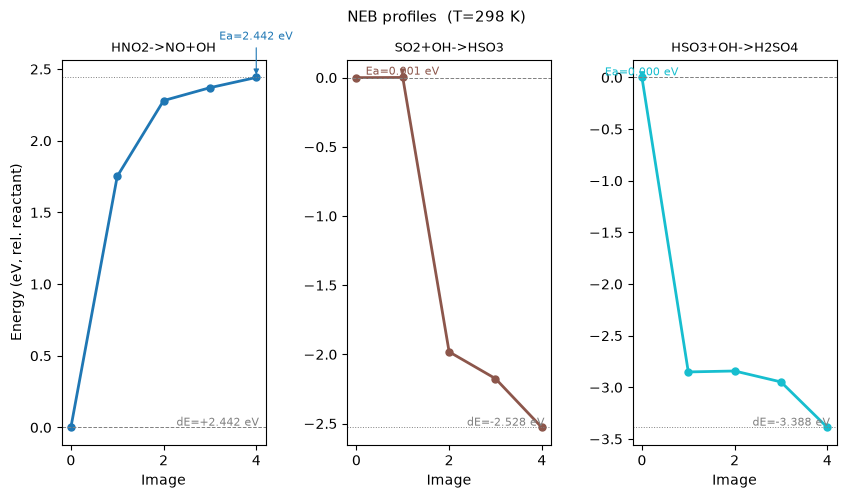

In [281]:
from claude_code.neb_runner import plot_energy_profiles
plot_energy_profiles(results)
plt.show()

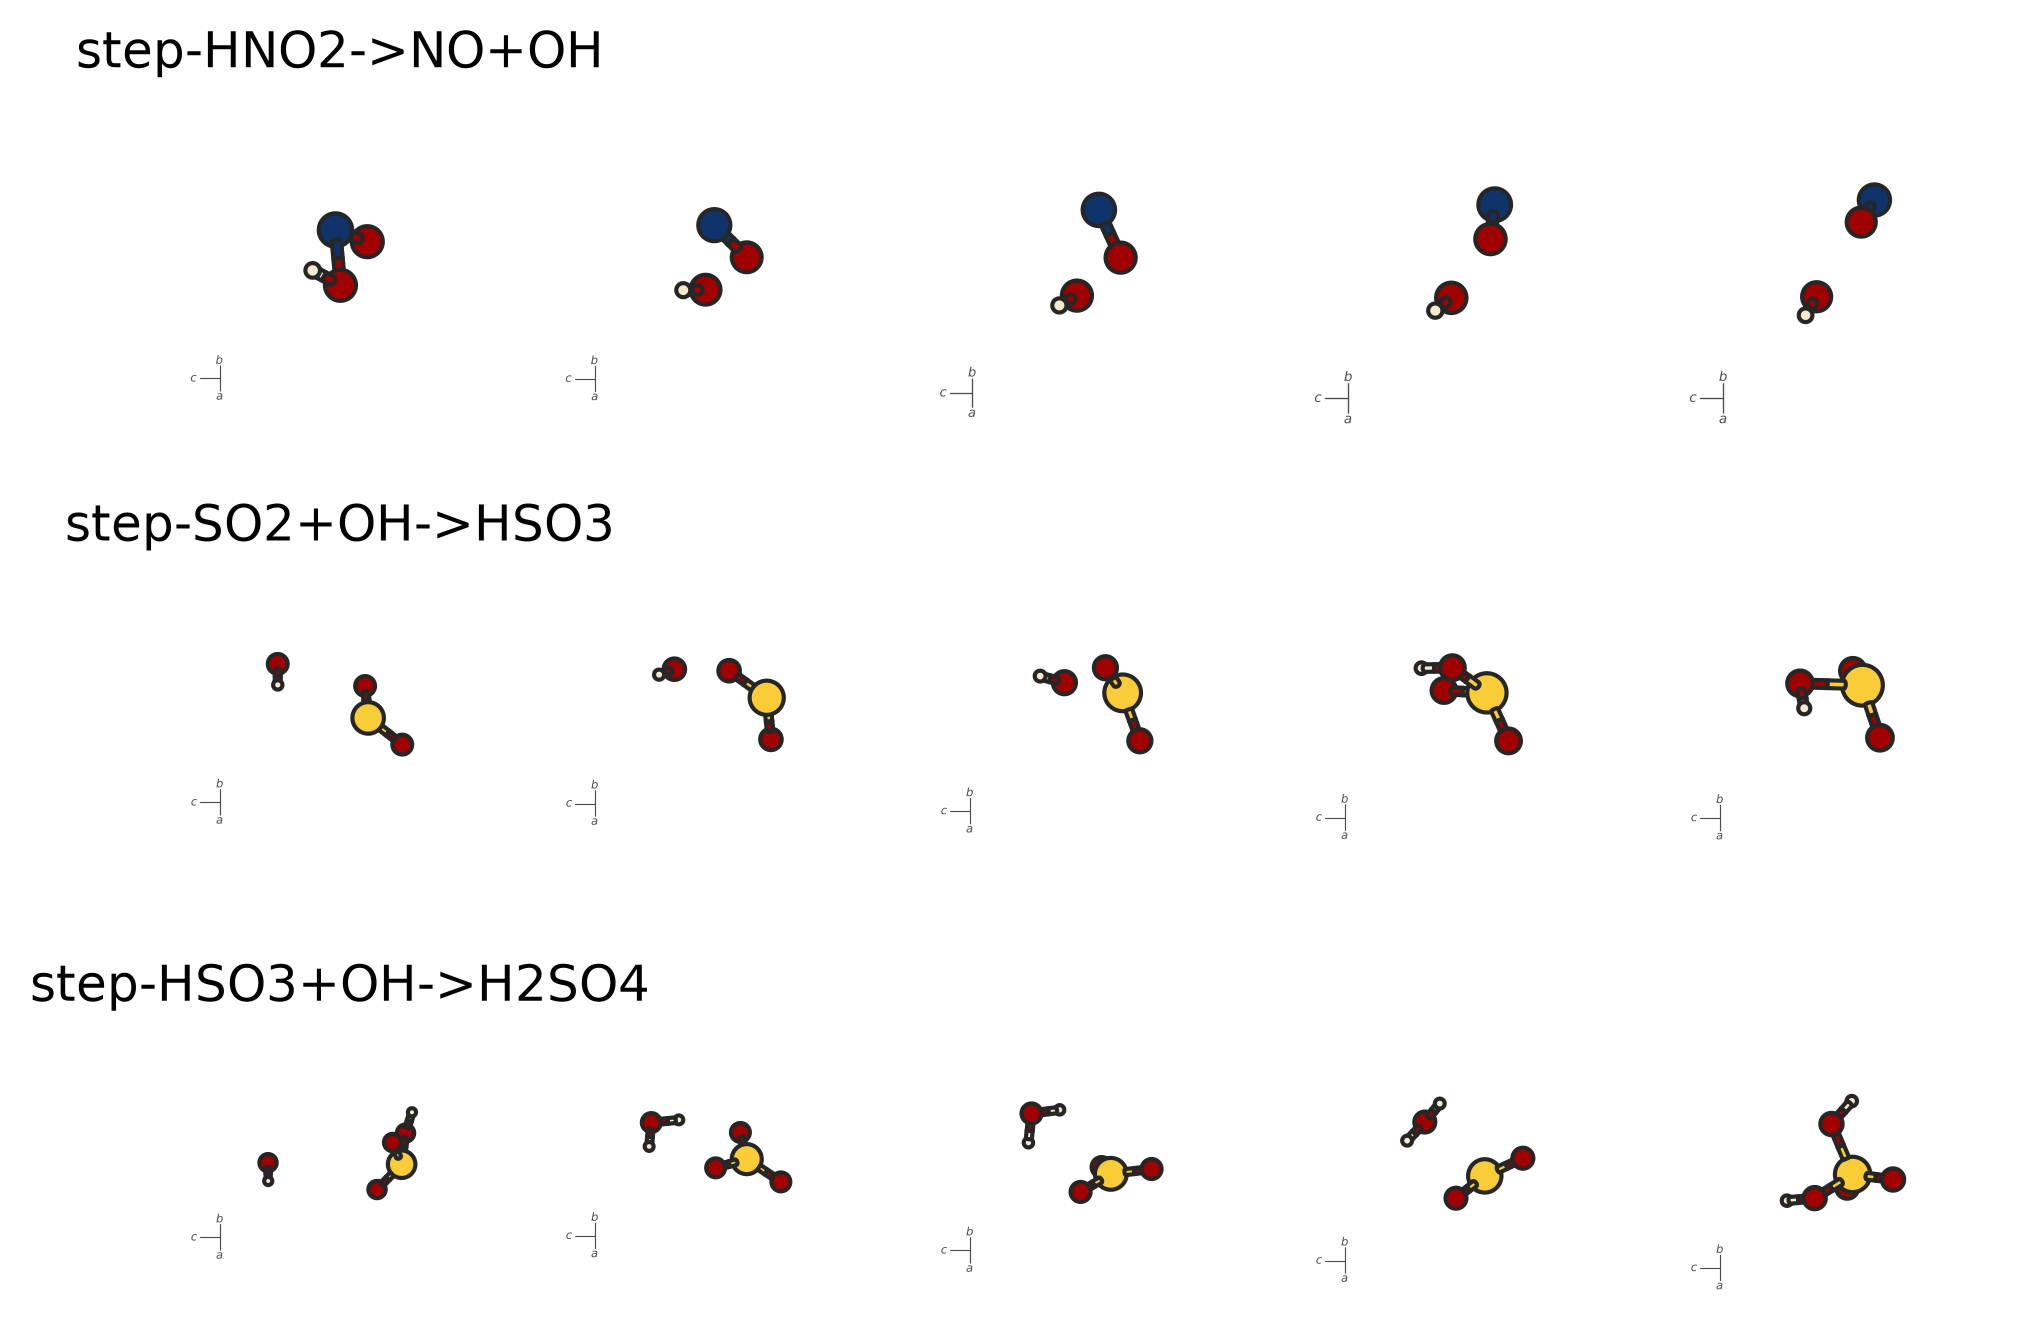

In [282]:
fig,axes = plt.subplots(nrows=len(results),ncols=len(results[0].images),dpi=300)
style = RenderStyle(
    cell_style=CellEdgeStyle(
        line_width=0
    ),
)
ax_flat = axes.flatten()
i = 0 
for result in results:
    ax_flat[i].set_title(f"step-{result.label}")
    for image in result.images:
        scene = StructureScene.from_pymatgen(aaa.get_structure(image))
        scene.view.zoom = 0.5  # Zoom in
        scene.view.look_along([1,1,0])
        scene.render_mpl(ax=ax_flat[i],style=style)
        i+=1
    


plt.tight_layout()

In [255]:
from ase.visualize import view 
view(results[0].images,viewer="ngl")


Microkinetic Model
  T = 298.0 K  |  P = 1.000 atm
  Concentration unit: ppm @ 298K/1.00atm  (1 unit = 4.0895e-08 mol/L)
  3 elementary steps  |  6 species
  Species: ['HNO2', 'NO', 'OH', 'SO2', 'HSO3', 'H2SO4']

  Prefactor kT/h = 6.209e+12 s⁻¹  (T = 298 K)
  HNO2->NO+OH
    Ea_fwd = 2.4417 eV  kf = 3.1568e-29  kr = 2.5393e+05  Keq = 1.2432e-34
  SO2+OH->HSO3
    Ea_fwd = 0.0014 eV  kf = 2.4074e+05  kr = 1.0354e-30  Keq = 2.3250e+35
  HSO3+OH->H2SO4
    Ea_fwd = 0.0000 eV  kf = 2.5393e+05  kr = 0.0000e+00  Keq = 2.5393e+305

  Solving steady state (algebraic)...
  Steady state converged.
  Computing degree of rate control (DRC)...
  Building time-evolution profile (LSODA, t=1.00e+03 s)...

MICROKINETIC MODEL REPORT
  T = 298.0 K  |  P = 1.000 atm
  Integration: converged

─────────────────────────────────────────────────────────────────
  Rate constants (Eyring, T = 298.0 K)
  Step                           kf (s⁻¹ or L/mol/s)                    kr
  ─────────────────────────────────

/Users/badw/github-projects/arcs-kinetics/notebooks/claude_code/microkinetic_model.py:923: RuntimeWarning: divide by zero encountered in divide
  keq = np.where(k_rev > 0, k_fwd / k_rev, np.inf)


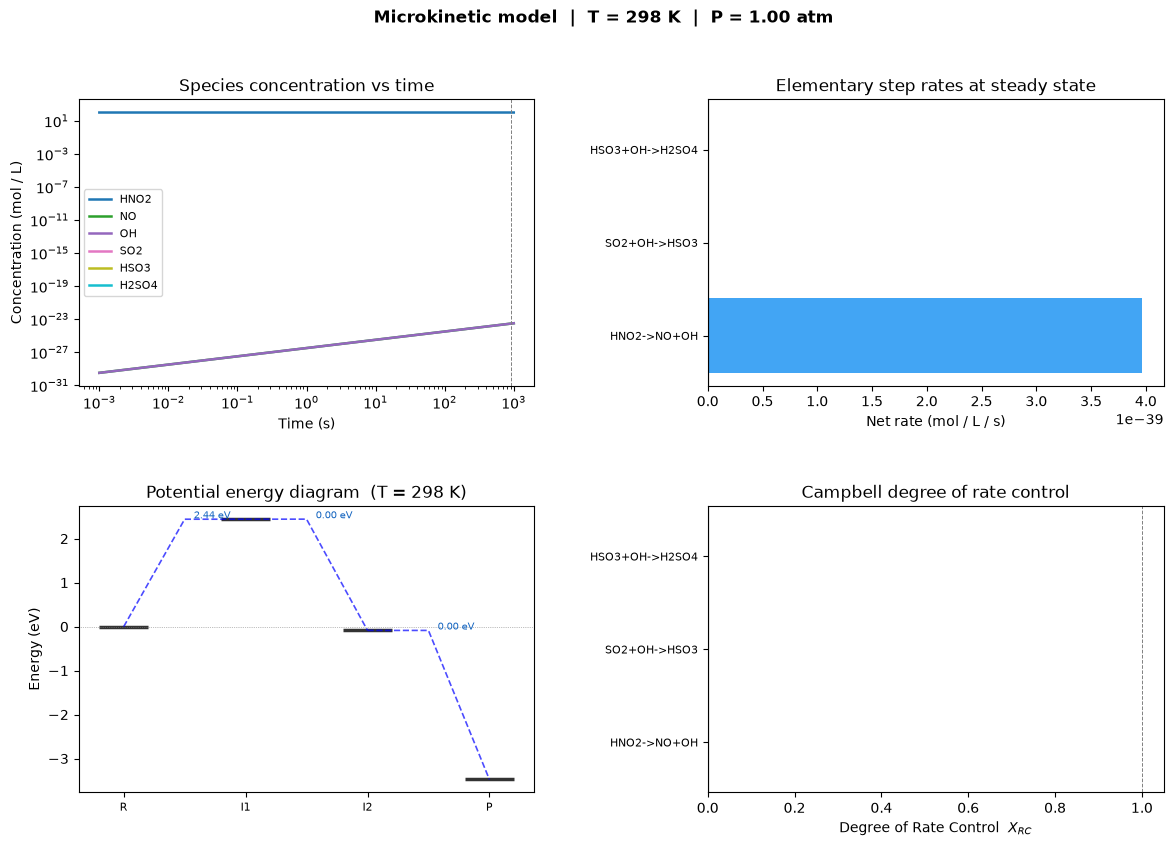

In [283]:
from claude_code.microkinetic_model import MicroKineticModel, ElementaryStep, ConcentrationUnit
from collections import Counter


# neb_results comes directly from runner.run_batch(...)
steps = [
    ElementaryStep(
        label=s["label"],
        reactants=Counter(r["reactants"]),
        products=Counter(r["products"]),
        neb_result=results[i],
    )
    
    for i, (s, r) in enumerate(zip(path_steps, route))
]

T = 298 
P = 1

model = MicroKineticModel(
    steps=steps,
    temperature=T,
    pressure=P,
    conc_unit=ConcentrationUnit.ppm(T=T, P_atm=P),
    initial_conc={"HNOSO4": 100.0, "HNO2": 100.0},   # 100 ppm NO, 50 ppm O2
    target_reaction="NOHSO4 + HNO2 = H2SO4 + NO2 + NO ",
    t_end=1000 #10
)

result = model.run()   # prints full report automatically
result.plot()
plt.show()

In [176]:
#chempy 

In [258]:
result.k_forward,result.k_reverse

(array([0.20511119]), array([0.01038118]))

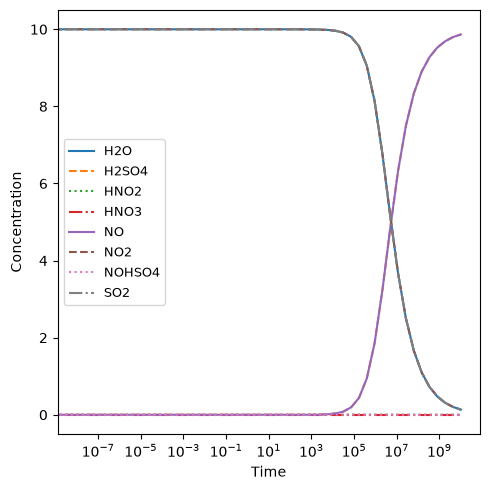

In [11]:
# The rate constants below are arbitrary
from chempy import ReactionSystem, Reaction
from chempy.kinetics.ode import get_odesys
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt

# rsys = ReactionSystem(
#    [
#        # {result.k_forward[0]}"),
#        Reaction.from_string(f"NO2 + NO2 -> N2O4 ; 10735"),
#        # {result.k_forward[1]}"),
#        Reaction.from_string(f"H2O + N2O4 -> HNO2 + HNO3 ; 2.8e-9"),
#        Reaction.from_string(f"SO2 + HNO3 -> NOHSO4 ; 420"),
#        Reaction.from_string(
#            f"NOHSO4 + HNO2 -> H2SO4 + NO2 + NO ; 2.5e-1"),#

#        Reaction.from_string(
#            f"HNO2 -> NO + OH ; {result.k_forward[0]}"),
#        Reaction.from_string(
#            f"SO2 + OH -> HSO3 ; {result.k_forward[1]}"),
#        Reaction.from_string(
#            f"HSO3 + OH -> H2SO4 ; {result.k_forward[2]}"),#
#

#    ]
# )

rsys = ReactionSystem(
    [
        Reaction.from_string(
            f"2 NO2 + H2O -> HNO3 + HNO2 ; 2.8e-9"
        ),
        Reaction.from_string(
            f"SO2 + HNO3 -> NOHSO4 ; 420"
        ),
        Reaction.from_string(
            f"NOHSO4 + HNO2 -> H2SO4 + NO2 + NO ; 2.5e-1"
        ),
        Reaction.from_string(
            f"SO2 + 2 HNO2 -> H2SO4 + 2 NO ; 2.8e-9"
        )
    ]
)
odesys, extra = get_odesys(rsys)

tout = sorted(np.concatenate((np.linspace(0, 23), np.logspace(-8, 10))))
c0 = defaultdict(float, {'H2O': 10, "NO2": 10, "SO2": 10, })
result_chempy = odesys.integrate(tout, c0, atol=1e-12, rtol=1e-14)
fig, axes = plt.subplots(1, 1, figsize=(5, 5))
for ax in [axes]:
    _ = result_chempy.plot(names=[k for k in rsys.substances], ax=ax)
    _ = ax.legend(loc='best', prop={'size': 9})
    _ = ax.set_xlabel('Time')
    _ = ax.set_ylabel('Concentration')
# _ = axes.set_ylim([0, ])
_ = axes.set_xscale('log')
# _ = axes.set_yscale('log')
_ = fig.tight_layout()
rsys

In [24]:
from reactit.reactit import ReactionGenerator

rg = ReactionGenerator(["SO2","NO2","NO","H2O","H2SO4","HNO2","NOHSO4","HNO3"])
rg.iterate()

  0%|          | 0/98 [00:00<?, ?it/s]

['1 SO2 + 1 HNO3 = 1 NOHSO4',
 '2 NO + 1 H2O + 1 HNO3 = 3 HNO2',
 '1 SO2 + 2 NO2 + 1 H2SO4 = 2 NOHSO4',
 '1 NO2 + 1 NO + 1 H2O = 2 HNO2',
 '1 SO2 + 2 HNO3 = 2 NO2 + 1 H2SO4',
 '1 SO2 + 2 HNO2 = 2 NO + 1 H2SO4',
 '2 NO2 + 1 H2O = 1 HNO2 + 1 HNO3',
 '2 NO2 + 1 H2SO4 = 1 NOHSO4 + 1 HNO3',
 '1 H2O + 1 NOHSO4 = 1 H2SO4 + 1 HNO2',
 '3 NO2 + 1 H2O = 1 NO + 2 HNO3',
 '1 NO2 + 1 HNO2 = 1 NO + 1 HNO3']

In [69]:
10 ** np.random.uniform(0.1,4,10) 


array([2651.6909051 ,  244.80231058,  346.38848572,   26.79823053,
         10.91855732,   51.05883523,   38.25674376,  101.87093415,
        715.91271045,  176.46058222])

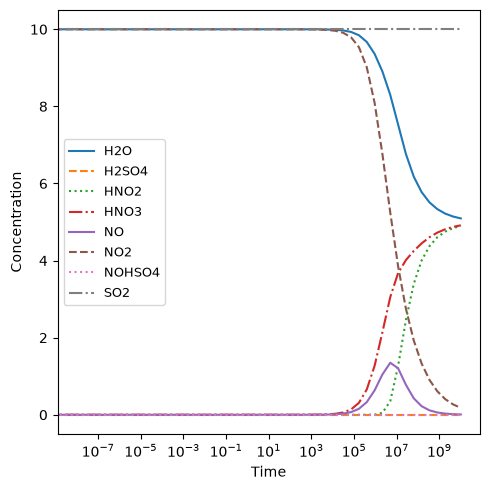

In [72]:
rsys = ReactionSystem([Reaction.from_string(r.replace('=','->')+f"; 1e-{np.random.randint(50)}") for r in rg.reactions])
odesys, extra = get_odesys(rsys)

tout = sorted(np.concatenate((np.linspace(0, 23), np.logspace(-8, 10))))
c0 = defaultdict(float, {'H2O': 10, "NO2": 10, "SO2": 10, })
result_chempy = odesys.integrate(tout, c0, atol=1e-12, rtol=1e-14)
fig, axes = plt.subplots(1, 1, figsize=(5, 5))
for ax in [axes]:
    _ = result_chempy.plot(names=[k for k in rsys.substances], ax=ax)
    _ = ax.legend(loc='best', prop={'size': 9})
    _ = ax.set_xlabel('Time')
    _ = ax.set_ylabel('Concentration')
# _ = axes.set_ylim([0, ])
_ = axes.set_xscale('log')
# _ = axes.set_yscale('log')
_ = fig.tight_layout()
rsys

(1.0, 1000.0)

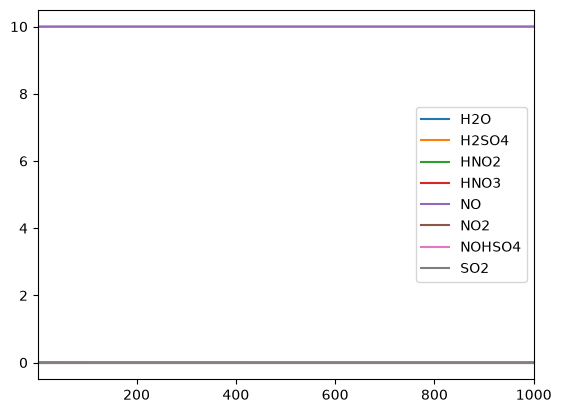

In [35]:
import pandas as pd 
df = pd.DataFrame(result_chempy[1],columns=result_chempy.names,index=result_chempy[0] / 60 / 60 )
ax = df.plot.line()
#ax.set_yscale("log") ; #ax.set_xscale("log")
ax.set_xlim(1e0,1000)

(1.0, 100000.0)

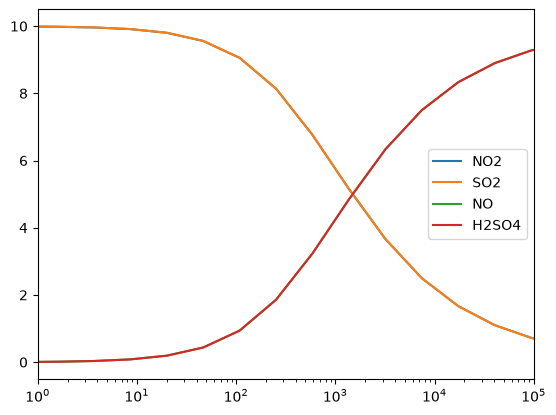

In [23]:
ax = df["NO2"].plot.line()
df["SO2"].plot.line(ax=ax)
df["NO"].plot.line(ax=ax)
df["H2SO4"].plot.line(ax=ax)

#ax.set_yscale("log")
ax.set_xscale("log")
ax.legend()
ax.set_xlim(1e0,1e5)

In [308]:
10**6 / 60 / 60 

277.77777777777777

In [299]:
df["SO2"]

0.000000e+00    1.000000
1.000000e-08    1.000000
1.842070e-08    1.000000
3.393222e-08    1.000000
6.250552e-08    1.000000
                  ...   
8.685114e+03    0.999988
1.599859e+04    0.999978
2.947052e+04    0.999959
5.428675e+04    0.999924
1.000000e+05    0.999860
Name: SO2, Length: 100, dtype: float64